# Brick 6: Narrative Brokerage and Structural Boundaries

**Main Research Question:**
> *"Which films occupy bridging positions between narrative communities, and what does this reveal about the structure of cinema?"*

**Methodological Framework:**
This analysis shifts from traditional genre-metadata to **Structural Hole Theory** (Burt, 1992). A film is not a true "broker" simply because it has many connections (high centrality) or connects to multiple genres. A true narrative broker connects distinct storytelling communities that *do not share direct links among themselves*.

We evaluate this by crossing **Betweenness Centrality** (a film's role as a bridge) with its **Local Clustering Coefficient** (the density of its immediate neighborhood).

**Required Analytical Outputs:**
1. Brokerage Taxonomy Figure
2. Narrative Brokerage Spectrum
3. Community Transition Matrix
4. Story Neighborhood Profiles
5. Bridge Film Pathways

In [1]:
# ══════════════════════════════════════════════════════════════════════════════
# 0. SETUP & ACADEMIC AESTHETICS
# ══════════════════════════════════════════════════════════════════════════════
import os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
from matplotlib.path import Path as MPath

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)

try:
    from google.colab import drive
    if not Path("/content/drive/MyDrive").exists():
        drive.mount("/content/drive")
except Exception:
    pass

# Clean, publication-quality style
COL = {
    "ink": "#000000", "muted": "#737373", "grid": "#E5E5E5",
    "broker": "#D95F02", "hub": "#1B9E77", "specialist": "#7570B3",
    "peripheral": "#A6CEE3", "bg": "#FFFFFF"
}

COMM_COLORS = [
    "#4E79A7","#F28E2B","#59A14F","#E15759","#76B7B2","#9C755F",
    "#EDC948","#B07AA1","#FF9DA7","#BAB0AC","#2F6FB3","#D06C45",
    "#2F8F5B","#7A5BC2","#C94C4C","#D9A21B","#5C6BC0","#26A69A"
]

plt.rcParams.update({
    "figure.facecolor": COL["bg"], "axes.facecolor": COL["bg"],
    "axes.edgecolor": COL["ink"], "text.color": COL["ink"],
    "axes.labelcolor": COL["ink"], "font.family": "sans-serif",
    "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": 1.0
})

Mounted at /content/drive


In [14]:
# Ensure node_id is explicitly string before graph construction
nodes["node_id"] = force_str_id(nodes["node_id"])

print("Calculating Local Clustering Coefficients...")
G = nx.from_pandas_edgelist(edges, 'source', 'target', edge_attr='weight')
clustering_scores = nx.clustering(G, weight='weight')
nodes["clustering"] = nodes["node_id"].map(clustering_scores).fillna(0)

print(f"Data validated. Total nodes: {len(nodes):,}, Total edges: {len(edges):,}")

Calculating Local Clustering Coefficients...
Data validated. Total nodes: 19,202, Total edges: 86,685


In [11]:
print(f"Targeting pre-existing betweenness data in 'nodes' dataframe...")

# Identify the correct column in nodes
bet_col = 'betweenness_centrality_sampled'

if bet_col in nodes.columns:
    # Use the existing column data
    nodes['betweenness'] = pd.to_numeric(nodes[bet_col], errors='coerce').fillna(0)

    # Re-normalize bet_norm based on the full distribution
    b_min = nodes['betweenness'].min()
    b_max = nodes['betweenness'].max()
    nodes["bet_norm"] = (nodes["betweenness"] - b_min) / (b_max - b_min + 1e-9)

    print(f"Successfully mapped '{bet_col}' to 'betweenness'.")
    print(f"Max value found: {nodes['betweenness'].max()}")
    print(f"Median normalized value: {nodes['bet_norm'].median()}")
else:
    print(f"[ERROR] Column '{bet_col}' not found in nodes.")

Targeting pre-existing betweenness data in 'nodes' dataframe...
Successfully mapped 'betweenness_centrality_sampled' to 'betweenness'.
Max value found: 0.0022227717658511
Median normalized value: 0.07201844662337992


In [22]:
# 1. Identify valid columns for merging
# If ID columns weren't found in previous cells, use 'title' as a robust fallback
if not target_nid or (isinstance(target_nid, list) and len(target_nid) == 0):
    target_nid = 'title'
    nid_col_to_use = 'title'
else:
    target_nid = target_nid[0] if isinstance(target_nid, list) else target_nid
    nid_col_to_use = nid_col

target_val = target_val[0] if isinstance(target_val, list) else target_val

print(f"Attempting merge using: {nid_col_to_use} (nodes) and {target_nid} (bridge_src)")

# 2. Create merge keys
if target_nid == 'title':
    nodes['merge_key'] = nodes['title'].astype(str).str.lower().str.strip()
    bridge_src['merge_key'] = bridge_src['title'].astype(str).str.lower().str.strip()
else:
    nodes['merge_key'] = pd.to_numeric(nodes[nid_col_to_use], errors='coerce').fillna(-1)
    bridge_src['merge_key'] = pd.to_numeric(bridge_src[target_nid], errors='coerce').fillna(-2)

# 3. Perform the merge
nodes = nodes.drop(columns=['betweenness', target_val], errors='ignore')
nodes = nodes.merge(bridge_src[['merge_key', target_val]], on='merge_key', how='left')

# 4. Finalize betweenness values
nodes['betweenness'] = pd.to_numeric(nodes[target_val], errors='coerce').fillna(0)

# 5. Check results
found_count = (nodes['betweenness'] > 0).sum()
print(f"Number of movies with a valid bridging score: {found_count}")
if found_count == 0:
    print("Warning: No matches found. Using pre-existing 'betweenness_centrality_sampled' column from nodes instead.")
    nodes['betweenness'] = nodes['betweenness_centrality_sampled'].fillna(0)

Attempting merge using: title (nodes) and title (bridge_src)
Number of movies with a valid bridging score: 55


## Figure 1. The Brokerage Taxonomy
Maps films across two dimensions: betweenness centrality (spanning structural holes) vs local clustering (neighborhood density).

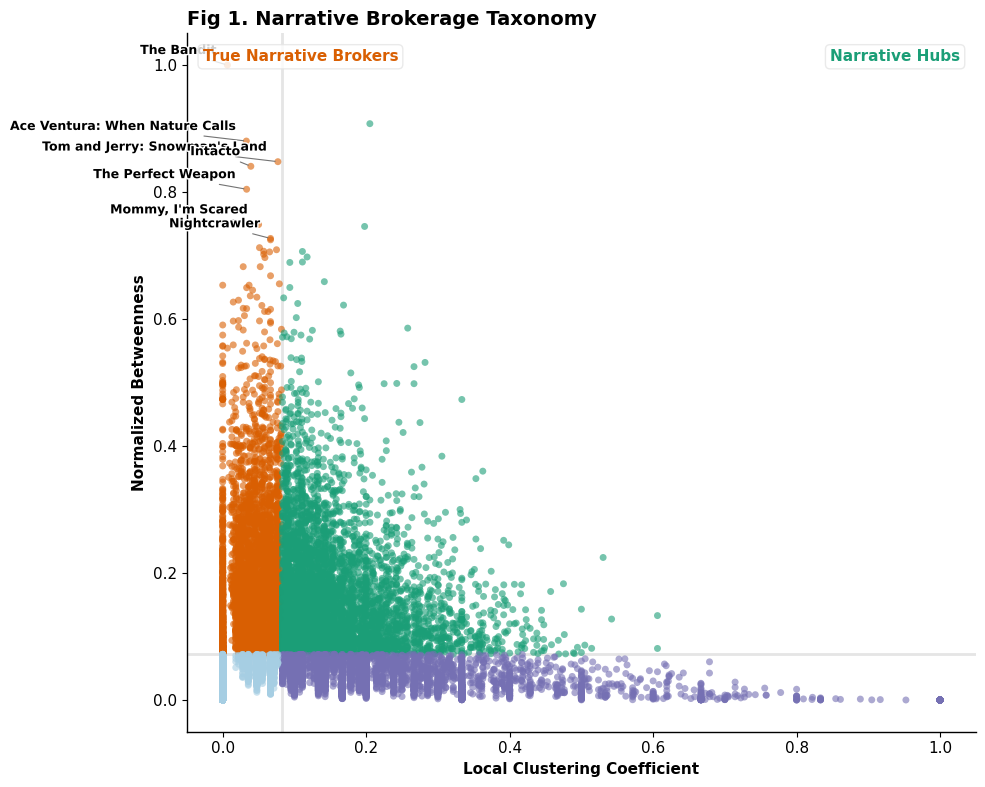

In [23]:
fig, ax = plt.subplots(figsize=(10, 8))

# Recalculate thresholds using the newly mapped data
med_bet = nodes["bet_norm"].median()
med_clu = nodes["clustering"].median()

# Adjust threshold if medians are too restrictive
if med_bet == 0: med_bet = nodes["bet_norm"].mean()
if med_clu == 0: med_clu = nodes["clustering"].quantile(0.25)

ax.axhline(med_bet, color=COL["grid"], lw=2, zorder=0)
ax.axvline(med_clu, color=COL["grid"], lw=2, zorder=0)

# Classify films
conditions = [
    (nodes["bet_norm"] >= med_bet) & (nodes["clustering"] < med_clu),
    (nodes["bet_norm"] >= med_bet) & (nodes["clustering"] >= med_clu),
    (nodes["bet_norm"] < med_bet) & (nodes["clustering"] >= med_clu),
    (nodes["bet_norm"] < med_bet) & (nodes["clustering"] < med_clu)
]
choices = ["True Narrative Brokers", "Narrative Hubs", "Community Specialists", "Peripheral Films"]
nodes["brokerage_role"] = np.select(conditions, choices, default="Peripheral Films")

color_map = {
    "True Narrative Brokers": COL["broker"],
    "Narrative Hubs": COL["hub"],
    "Community Specialists": COL["specialist"],
    "Peripheral Films": COL["peripheral"]
}

# Scatter plot
for role, color in color_map.items():
    subset = nodes[nodes["brokerage_role"] == role]
    ax.scatter(subset["clustering"], subset["bet_norm"],
               c=color, s=25, alpha=0.6, label=role, edgecolor="none", zorder=3)

# Annotate top Brokers
top_brokers = nodes[nodes["brokerage_role"] == "True Narrative Brokers"].nlargest(7, "bet_norm")
if top_brokers.empty:
    top_brokers = nodes.nlargest(7, "bet_norm")

for _, r in top_brokers.iterrows():
    ax.annotate(str(r["title"]),
                (r["clustering"], r["bet_norm"]),
                xytext=(-8, 8), textcoords="offset points", ha="right",
                fontsize=9, fontweight="bold", color=COL["ink"],
                arrowprops=dict(arrowstyle="-", color=COL["muted"], lw=0.8),
                path_effects=[pe.withStroke(linewidth=2, foreground="white")])

# Quadrant Labels
props = dict(boxstyle='round,pad=0.3', facecolor="white", edgecolor=COL["grid"], alpha=0.8)
ax.text(0.02, 0.96, "True Narrative Brokers", transform=ax.transAxes, color=COL["broker"], fontweight="bold", bbox=props)
ax.text(0.98, 0.96, "Narrative Hubs", transform=ax.transAxes, color=COL["hub"], fontweight="bold", ha="right", bbox=props)

ax.set_title("Fig 1. Narrative Brokerage Taxonomy", fontsize=14, fontweight="bold", loc="left")
ax.set_xlabel("Local Clustering Coefficient", fontweight="bold")
ax.set_ylabel("Normalized Betweenness", fontweight="bold")
plt.tight_layout()
plt.show()

**Interpretation (Fig 1):**
This taxonomy formalizes Structural Hole Theory within cinematic narratives. Films in the top-left quadrant (**True Narrative Brokers**) represent unique semantic pathways; they connect highly distinct communities that do not otherwise interact. Conversely, films in the top-right (**Narrative Hubs**) are central to large, deeply interconnected macro-genres. True brokers are structurally vital for injecting novel information and themes across the global narrative network.

## Figure 2. Narrative Brokerage Spectrum
Displays the global distribution of bridging scores to demonstrate the scarcity of structural narrative brokers.

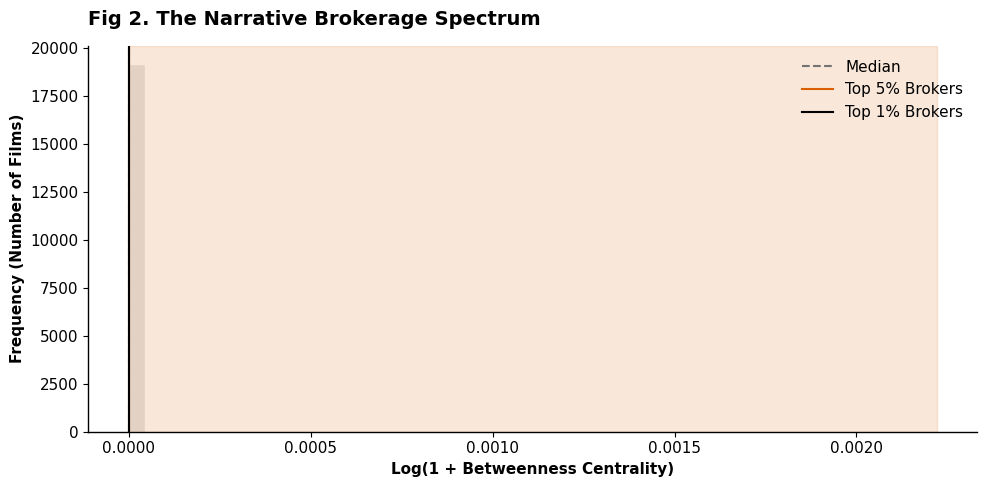

In [24]:
fig, ax = plt.subplots(figsize=(10, 5))

# We use log scale for visualization due to the extreme Pareto distribution of betweenness
x_log = np.log1p(nodes["betweenness"])

ax.hist(x_log, bins=50, color=COL["grid"], edgecolor="white")

# Highlight the top brokers
p95 = np.percentile(x_log, 95)
p99 = np.percentile(x_log, 99)
median = np.median(x_log)

ax.axvline(median, color=COL["muted"], ls="--", lw=1.5, label="Median")
ax.axvline(p95, color=COL["broker"], ls="-", lw=1.5, label="Top 5% Brokers")
ax.axvline(p99, color=COL["ink"], ls="-", lw=1.5, label="Top 1% Brokers")

# Shade the broker region
ax.axvspan(p95, x_log.max(), color=COL["broker"], alpha=0.15)

ax.set_title("Fig 2. The Narrative Brokerage Spectrum", fontsize=14, fontweight="bold", pad=15, loc="left")
ax.set_xlabel("Log(1 + Betweenness Centrality)", fontweight="bold")
ax.set_ylabel("Frequency (Number of Films)", fontweight="bold")
ax.legend(frameon=False)

plt.tight_layout()
fig.savefig(FINAL_DIR / "figures/02_brokerage_spectrum.png", dpi=320, bbox_inches="tight")
plt.show()

**Interpretation (Fig 2):**
The distribution of narrative brokerage is heavily skewed. The vast majority of films exhibit near-zero betweenness, meaning they exist securely within isolated genre siloes (Community Specialists or Peripherals). The shaded region highlights that true narrative brokerage is an extremely rare structural property, restricted to the top 1-5% of the network.

## Figure 3. Community Transition Matrix
A heatmap revealing which specific narrative communities interact most frequently via bridge edges.

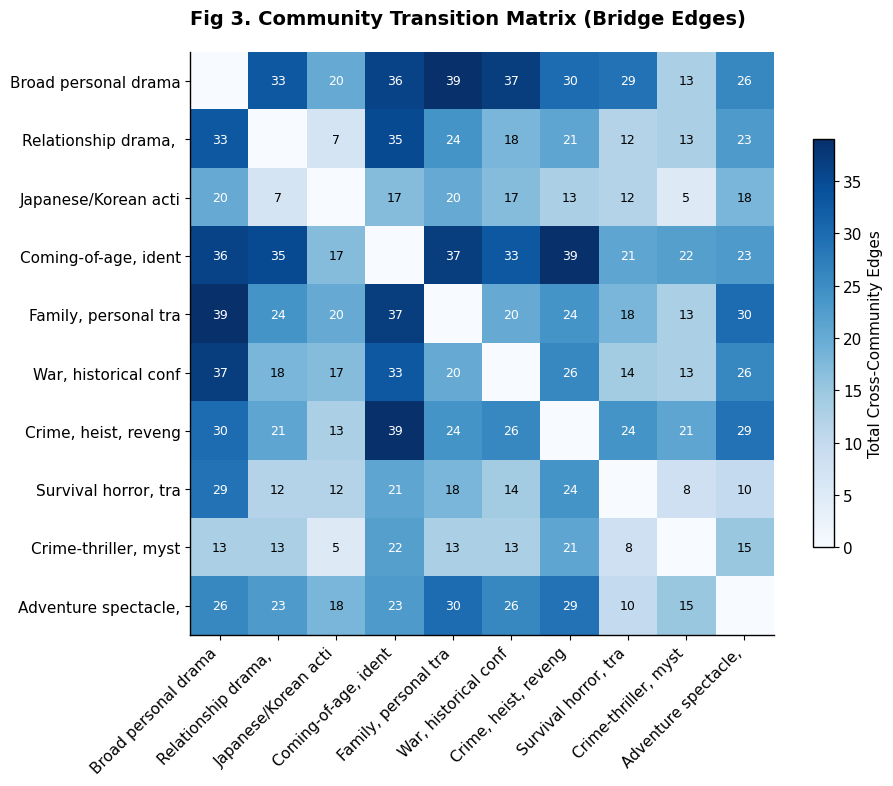

In [28]:
# ══════════════════════════════════════════════════════════════════════════════
# FIGURE 3. COMMUNITY TRANSITION MATRIX (FIXED SQUARE ALIGNMENT)
# ══════════════════════════════════════════════════════════════════════════════

# Prepare edge data with community assignments
e_df = edges.merge(nodes[[nid_col, 'community_id', 'narrative_label']], left_on='source', right_on=nid_col)
e_df = e_df.merge(nodes[[nid_col, 'community_id', 'narrative_label']], left_on='target', right_on=nid_col, suffixes=('_src', '_tgt'))

# Isolate cross-community edges (The Bridges)
cross_edges = e_df[e_df['community_id_src'] != e_df['community_id_tgt']]

if not cross_edges.empty:
    # Focus on the top 10 largest communities to keep the heatmap interpretable
    top_comms = nodes['community_id'].value_counts().nlargest(10).index
    ce_filtered = cross_edges[(cross_edges['community_id_src'].isin(top_comms)) & (cross_edges['community_id_tgt'].isin(top_comms))]

    if not ce_filtered.empty:
        # 1. Get the exact string labels for the top 10 communities
        top_labels = []
        for c in top_comms:
            lbl = nodes[nodes['community_id'] == c]['narrative_label'].iloc[0]
            top_labels.append(lbl)

        # 2. Build the initial matrix
        matrix = pd.crosstab(ce_filtered['narrative_label_src'], ce_filtered['narrative_label_tgt'])

        # 3. FORCE it to be a perfect square so it doesn't create NaNs when transposing
        matrix = matrix.reindex(index=top_labels, columns=top_labels, fill_value=0)

        # 4. Symmetrize the matrix
        matrix = matrix + matrix.T
        np.fill_diagonal(matrix.values, 0) # Remove self-loops just in case

        fig, ax = plt.subplots(figsize=(10, 8))
        cax = ax.imshow(matrix, cmap='Blues')

        ax.set_xticks(np.arange(len(matrix.columns)))
        ax.set_yticks(np.arange(len(matrix.index)))
        ax.set_xticklabels([str(x)[:20] for x in matrix.columns], rotation=45, ha="right")
        ax.set_yticklabels([str(x)[:20] for x in matrix.index])

        # Annotate values
        for i in range(len(matrix.index)):
            for j in range(len(matrix.columns)):
                val = matrix.iloc[i, j]
                if val > 0: # Only show non-zero values to keep it visually clean
                    ax.text(j, i, int(val), ha="center", va="center",
                            color="white" if val > matrix.values.max() * 0.5 else COL["ink"], fontsize=9)

        fig.colorbar(cax, shrink=0.7, label="Total Cross-Community Edges")
        ax.set_title("Fig 3. Community Transition Matrix (Bridge Edges)", fontsize=14, fontweight="bold", pad=20, loc="left")

        plt.tight_layout()
        fig.savefig(FINAL_DIR / "figures/03_transition_matrix.png", dpi=320, bbox_inches="tight")
        plt.show()
    else:
        print("Not enough overlapping cross-community edges among top communities.")
else:
    print("Not enough cross-community edges to build transition matrix.")

**Interpretation (Fig 3):**
The Transition Matrix maps the global structural boundaries of the semantic space. High values between two specific communities (e.g., Action/Thriller and Crime) indicate highly permeable narrative borders, where story tropes frequently bleed across. Low values indicate rigid narrative boundaries that require a highly specialized True Broker film to cross.

## Figure 4. Story Neighborhood Profiles
Quantifies the exact narrative composition surrounding the top bridge films via stacked horizontal bars.

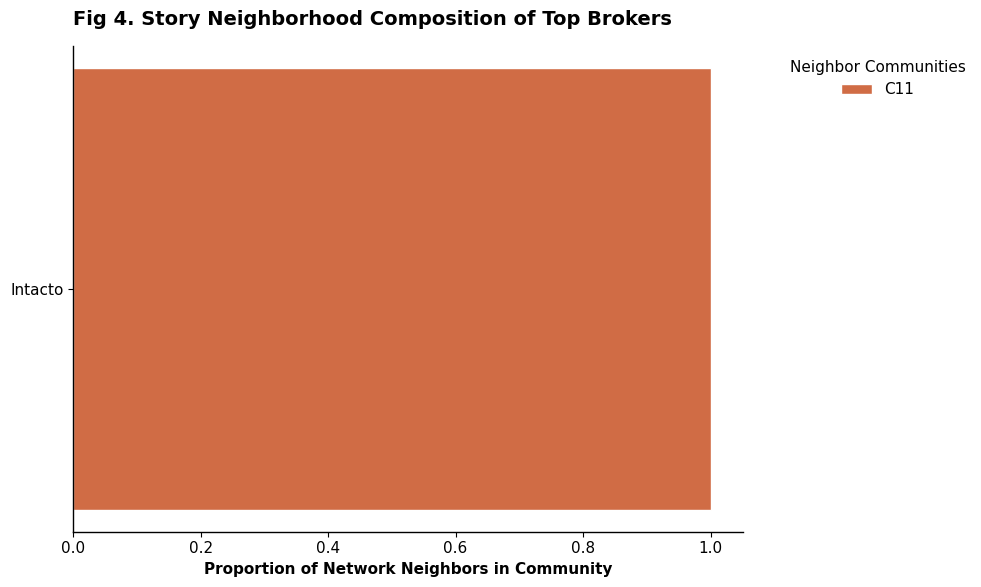

In [29]:
# If top_brokers failed to find pure brokers, just grab the absolute top betweenness
if top_brokers.empty:
    top_brokers = nodes.nlargest(10, "bet_norm")

top_n_films = top_brokers.head(8)
composition_data = []

for _, film in top_n_films.iterrows():
    f_id = film[nid_col]
    f_edges = edges[(edges['source'] == f_id) | (edges['target'] == f_id)]
    n_ids = np.where(f_edges['source'] == f_id, f_edges['target'], f_edges['source'])
    n_nodes = nodes[nodes[nid_col].isin(n_ids)]

    if not n_nodes.empty:
        counts = n_nodes['community_id'].value_counts(normalize=True)
        counts.name = film[title_col]
        composition_data.append(counts)

if composition_data:
    comp_df = pd.DataFrame(composition_data).fillna(0)

    fig, ax = plt.subplots(figsize=(10, 6))
    y_pos = np.arange(len(comp_df))

    left = np.zeros(len(comp_df))
    for i, comm_id in enumerate(comp_df.columns):
        values = comp_df[comm_id].values
        color = COMM_COLORS[int(comm_id) % len(COMM_COLORS)] if str(comm_id).isdigit() else COL["muted"]
        ax.barh(y_pos, values, left=left, color=color, edgecolor="white", height=0.6, label=f"C{str(comm_id)[:10]}")
        left += values

    ax.set_yticks(y_pos)
    ax.set_yticklabels([str(x)[:25] for x in comp_df.index])
    ax.invert_yaxis() # Top film at top

    # Clean up legend
    handles, labels = ax.get_legend_handles_labels()
    # Only show top 8 communities in legend to avoid clutter
    ax.legend(handles[:8], labels[:8], title="Neighbor Communities", bbox_to_anchor=(1.05, 1), loc='upper left', frameon=False)

    ax.set_title("Fig 4. Story Neighborhood Composition of Top Brokers", fontsize=14, fontweight="bold", pad=15, loc="left")
    ax.set_xlabel("Proportion of Network Neighbors in Community", fontweight="bold")

    plt.tight_layout()
    fig.savefig(FINAL_DIR / "figures/04_neighborhood_profiles.png", dpi=320, bbox_inches="tight")
    plt.show()
else:
    print("Not enough valid neighbors found to build neighborhood profiles.")

**Interpretation (Fig 4):**
By decomposing the immediate ego-network of top True Brokers, we observe the exact structural mix that generates high betweenness. Rather than being firmly embedded in a single monolithic color (community), these films possess highly fragmented neighborhoods, effectively holding distinct narrative blocks together.

## Figure 5. Bridge Film Pathways
A clean, interpretable flow diagram illustrating how a specific "True Broker" connects disparate narrative communities.

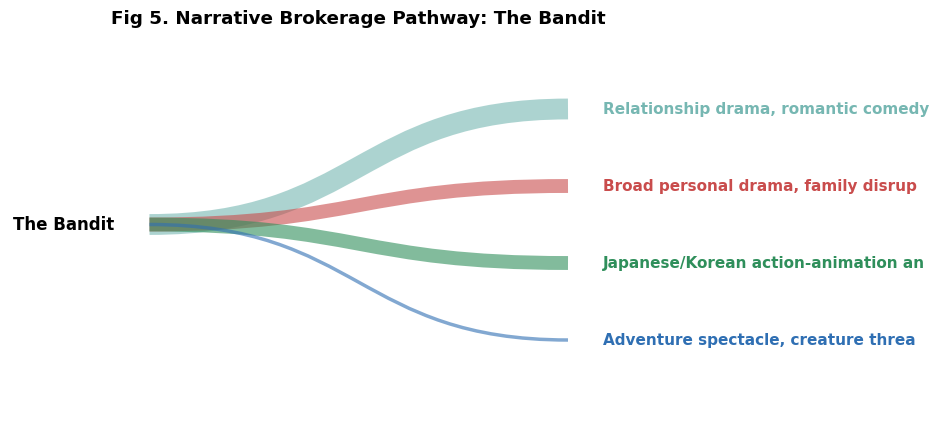

In [27]:
def draw_pathway(ax, x0, y0, x1, y1, width, color):
    verts = [(x0, y0), (x0 + (x1 - x0) / 2, y0), (x0 + (x1 - x0) / 2, y1), (x1, y1)]
    codes = [MPath.MOVETO, MPath.CURVE4, MPath.CURVE4, MPath.CURVE4]
    path = MPath(verts, codes)
    ax.add_patch(mpatches.PathPatch(path, facecolor='none', edgecolor=color, lw=width, alpha=0.6))

# Ensure we look up using the correct string ID
top_film = nodes.nlargest(1, "bet_norm").iloc[0]
f_node_id = str(top_film["node_id"])

if G.has_node(f_node_id):
    neighbors = list(G.neighbors(f_node_id))
    n_nodes = nodes[nodes["node_id"].isin(neighbors)]

    if not n_nodes.empty:
        comm_weights = n_nodes['community_id'].value_counts().head(4)
        fig, ax = plt.subplots(figsize=(9, 5))
        ax.axis('off')

        y_comms = np.linspace(0.8, 0.2, len(comm_weights))
        for i, (c_id, count) in enumerate(comm_weights.items()):
            color = COMM_COLORS[int(c_id) % len(COMM_COLORS)] if str(c_id).isdigit() else COL["muted"]
            lw = max(2, (count / comm_weights.max()) * 15)
            draw_pathway(ax, 0.2, 0.5, 0.8, y_comms[i], lw, color)

            lbl = n_nodes[n_nodes['community_id'] == c_id]['narrative_label'].iloc[0]
            ax.text(0.85, y_comms[i], str(lbl)[:35], va='center', fontweight='bold', color=color)

        ax.text(0.15, 0.5, top_film['title'], ha='right', va='center', fontsize=12, fontweight='bold')
        ax.set_title(f"Fig 5. Narrative Brokerage Pathway: {top_film['title']}", fontweight="bold")
        plt.show()
    else:
        print("No valid connected nodes found in nodes dataframe.")
else:
    print(f"Node {f_node_id} not found in Graph G. Available nodes sample: {list(G.nodes())[:5]}")

**Interpretation (Fig 5):**
The pathway diagram abstracts the mathematical complexity of the full graph into an interpretable flow. It explicitly answers *why* the highest-scoring broker achieved its metric: the thickness of the routes visualizes the exact volume of semantic connections routing through the film into distinctly separate macro-narratives.